# 양서연 · 교통량 변화와 도로 군집 분석

최신 **Train·Dev 결과만** 읽는다. Test 시즌은 열지 않는다. 수정 전 20261126 군집 결과는 결측 분모 오류로 최종 분석에서 제외한다.

In [9]:
# [서연] 조회 전용 환경 — 분석을 자동 실행하지 않는다.
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
RUN_BUILD = False
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'README.md').exists() and (p / '.git').exists())
TABLES = ROOT / 'outputs' / 'tables'
FIGURES = ROOT / 'outputs' / 'figures' / 'ysy'
LOGS = ROOT / 'logs' / 'ysy' / 'traffic_analysis'
print('저장소:', ROOT)
print('RUN_BUILD:', RUN_BUILD, '(기존 결과만 조회)')

저장소: C:\Users\USER\seoul-weather-traffic
RUN_BUILD: False (기존 결과만 조회)


In [10]:
# [서연] 수정 후 최신 군집 결과
analysis_log = sorted(LOGS.glob('traffic_analysis_*_(성공)_v*.json'))[-1]
report = json.loads(analysis_log.read_text(encoding='utf-8'))
display(pd.DataFrame([{'입력 행': report['rows']['source'], '도로': report['rows']['train_roads'], '유효 쌍': report['pairing']['valid_pairs'], '최적 k': report['clustering']['best_k'], '실루엣': report['clustering']['silhouette_scores'][str(report['clustering']['best_k'])], 'Train 도로': report['clustering']['clustered_roads'], 'Dev 도로': report['clustering']['dev_clustered_roads'], 'Dev 미분류': report['clustering']['dev_unclustered_roads'], 'Train·Dev 일치율': report['clustering']['train_dev_cluster_agreement_rate'], 'Test 제외': report.get('excluded_model_set') == 'test'}]))
print('최신 로그:', analysis_log.name)

,입력 행,도로,유효 쌍,최적 k,실루엣,Train 도로,Dev 도로,Dev 미분류,Train·Dev 일치율,Test 제외
0,50400,52,19037,6,0.322581,52,51,1,0.254902,True


최신 로그: traffic_analysis_20261127T004037_(성공)_v01.json


### 수정 및 실패 분석

기존 `decrease_share = values.lt(0).mean()`은 결측을 ‘감소하지 않음’으로 포함했다. 104개 도로×분할 특징 중 40개가 영향을 받았고 최대 차이는 0.711이었다. 결측을 분모에서 제외하도록 수정했다. 수정 후에도 군집 안정성이 낮으므로 수집 오류가 아니라 표본 수·관측률·계절별 반응 차이의 영향도 크다고 판단한다.

In [11]:
# [서연] K-means와 DTW 최신 결과
cluster_summary = pd.read_csv(sorted(TABLES.glob('yang_seoyeon_road_cluster_summary_*_(성공)_v*.csv'))[-1], encoding='utf-8-sig')
dtw = pd.read_csv(sorted(TABLES.glob('yang_seoyeon_dtw_clusters_*_(성공)_v*.csv'))[-1], encoding='utf-8-sig')
display(cluster_summary)
display(dtw.groupby(['split', 'dtw_cluster'], dropna=False).size().rename('도로 수').reset_index())

,model_set,cluster,road_count,median_change_pct,median_change_iqr,median_decrease_share,morning_median,evening_median,rain_median,snow_median,median_valid_road_hours
0,dev,0.0,11,-3.422502,6.754325,0.777778,-3.782349,-3.201708,-2.822891,-10.528802,45.0
1,dev,1.0,3,-0.783993,12.353330,0.571429,-2.686559,0.725561,-2.887811,3.007311,35.0
2,dev,2.0,7,-3.635204,10.259291,0.657143,-4.885270,-2.573099,-3.602057,-5.968333,45.0
3,dev,4.0,28,-5.883547,8.399331,0.800000,-7.114461,-5.932349,-5.210054,-8.607784,45.0
4,dev,5.0,2,-7.459360,13.582288,0.834091,-4.964263,-9.064728,-4.804550,-22.700621,36.5
5,train,0.0,21,-2.772903,6.361635,0.723810,-1.436311,-3.960472,-2.422862,-3.365064,105.0
6,train,1.0,17,-1.695281,8.259779,0.623529,-1.005837,-2.331744,-1.084696,-3.859711,99.0
7,train,2.0,8,-3.294731,10.307665,0.676984,-3.115346,-3.376655,-3.049039,-4.451554,105.0
8,train,3.0,2,-2.589868,10.782472,0.630075,1.784193,-6.538864,-2.182341,-14.477193,71.5
9,train,4.0,2,-5.281290,9.212878,0.757143,-6.181293,-4.524401,-4.935286,-5.753238,105.0


,split,dtw_cluster,도로 수
0,dev,0.0,12
1,dev,1.0,38
2,dev,NaN,2
3,train,0.0,2
4,train,1.0,50


In [12]:
# [서연] Gi*와 Isolation Forest 결과
gi = pd.read_csv(sorted(TABLES.glob('yang_seoyeon_gi_hotspots_*_(성공)_v*.csv'))[-1], encoding='utf-8-sig')
anomaly = pd.read_csv(sorted(TABLES.glob('yang_seoyeon_anomaly_summary_*_(성공)_v*.csv'))[-1], encoding='utf-8-sig')
display(gi.groupby(['split', 'k', 'hotspot_status']).size().rename('도로 수').reset_index())
display(anomaly)
print('Gi*: 9,999회 순열검정·BH 보정. 이상 후보는 원인이나 사고를 의미하지 않는다.')

,split,k,hotspot_status,도로 수
0,dev,4,not_significant,52
1,dev,6,not_significant,52
2,dev,8,not_significant,52
3,train,4,not_significant,52
4,train,6,not_significant,52
5,train,8,not_significant,52


,split,rows,valid,anomalies
0,dev,2340,2083,220
1,train,5460,4677,234


Gi*: 9,999회 순열검정·BH 보정. 이상 후보는 원인이나 사고를 의미하지 않는다.


In [13]:
# [서연] 뉴스 연결 결과
news_log = sorted(LOGS.glob('traffic_news_join_*_(성공)_v*.json'))[-1]
news_report = json.loads(news_log.read_text(encoding='utf-8'))
display(pd.DataFrame([{'뉴스 후보': news_report['news_candidates'], '교통 자료 연결': news_report['traffic_matched'], '분석 후보': news_report['eligible_candidates'], '고유 기사': news_report['eligible_unique_articles']}]))
print(news_report['limitations'])

,뉴스 후보,교통 자료 연결,분석 후보,고유 기사
0,335,324,59,34


제목 기반 검토 후보만 연결; 사건일·시간·원인 미확인. 뉴스는 학습에 사용하지 않음. 도로·날짜별 중앙값은 관측 출퇴근 시간에 한정.


In [14]:
# [서연] 대표 사례 5건 — 수동 검토 우선순위
case_path = sorted(TABLES.glob('yang_seoyeon_representative_cases_*_(성공)_v*.csv'))[-1]
cases = pd.read_csv(case_path, encoding='utf-8-sig')
show = ['representative_order', 'split', 'event_date', 'road_id', 'road_name', 'hour', 'case_type', 'anomaly_score', 'volume_change_pct_median', 'travel_time_change_pct_median', 'evidence_level', 'representative_title', 'manual_review_status']
display(cases[show])
print('기사 본문·실제 사건 시각·통제 여부·인과관계는 자동 확정하지 않았다.')

,representative_order,split,event_date,road_id,road_name,hour,case_type,anomaly_score,volume_change_pct_median,travel_time_change_pct_median,evidence_level,representative_title,manual_review_status
0,1,train,2024-07-17,R006,동부간선도로,9,통행시간 급증·교통량 감소,0.610629,-22.566372,54.045445,뉴스·통제표현 후보 있음,수도권 폭우로 출근길 대혼잡 우려..동부간선도로 통제,기사 본문·사건일·실제 통제·인과관계 미확인
1,2,dev,2024-11-27,R075,종로,20,통행시간 감소·교통량 감소,0.603274,-18.334656,-33.944505,뉴스 제목 후보 있음,"오세훈, 종로 부암동 찾아 '폭설 출근길' 제설작업 점검",기사 본문·사건일·실제 통제·인과관계 미확인
2,3,train,2024-07-17,R005,내부순환로,9,통행시간 급증·교통량 감소,0.580393,-12.247113,53.587576,뉴스·통제표현 후보 있음,집중호우에 서울 동부간선도로·내부순환로 교통 통제,기사 본문·사건일·실제 통제·인과관계 미확인
3,4,train,2024-02-20,R009,서부간선지하도로,19,통행시간 급증,0.670237,16.709341,201.061716,수치 이상만 확인,NaN,기사 본문·사건일·실제 통제·인과관계 미확인
4,5,train,2024-02-22,R003,경부고속도로,19,복합 이상,0.649146,20.475621,-47.779845,수치 이상만 확인,NaN,기사 본문·사건일·실제 통제·인과관계 미확인


기사 본문·실제 사건 시각·통제 여부·인과관계는 자동 확정하지 않았다.


In [15]:
# [서연] 최소 군집 크기·관측률 민감도
sensitivity_path = sorted(TABLES.glob('yang_seoyeon_cluster_sensitivity_selected_*_(성공)_v*.csv'))[-1]
cluster_sensitivity = pd.read_csv(sensitivity_path, encoding='utf-8-sig')
display(cluster_sensitivity[['coverage_rule', 'k', 'silhouette', 'train_roads', 'dev_roads', 'train_min_cluster_size', 'comparable_roads', 'same_cluster_roads', 'agreement_rate', 'excluded_road_hours']])
print('관측률과 최소 군집 크기를 바꿔도 낮은 일치율이 유지되는지 확인한 실패 원인 분석이다.')

,coverage_rule,k,silhouette,train_roads,dev_roads,train_min_cluster_size,comparable_roads,same_cluster_roads,agreement_rate,excluded_road_hours
0,전체,4,0.296314,52,51,5,51,14,0.274510,0
1,관측률_50%이상,2,0.304748,52,51,14,51,17,0.333333,195
2,관측률_100%,2,0.381554,51,42,11,42,14,0.333333,2263


관측률과 최소 군집 크기를 바꿔도 낮은 일치율이 유지되는지 확인한 실패 원인 분석이다.


cluster_train_dev_20261127T004103_(성공)_v01.png


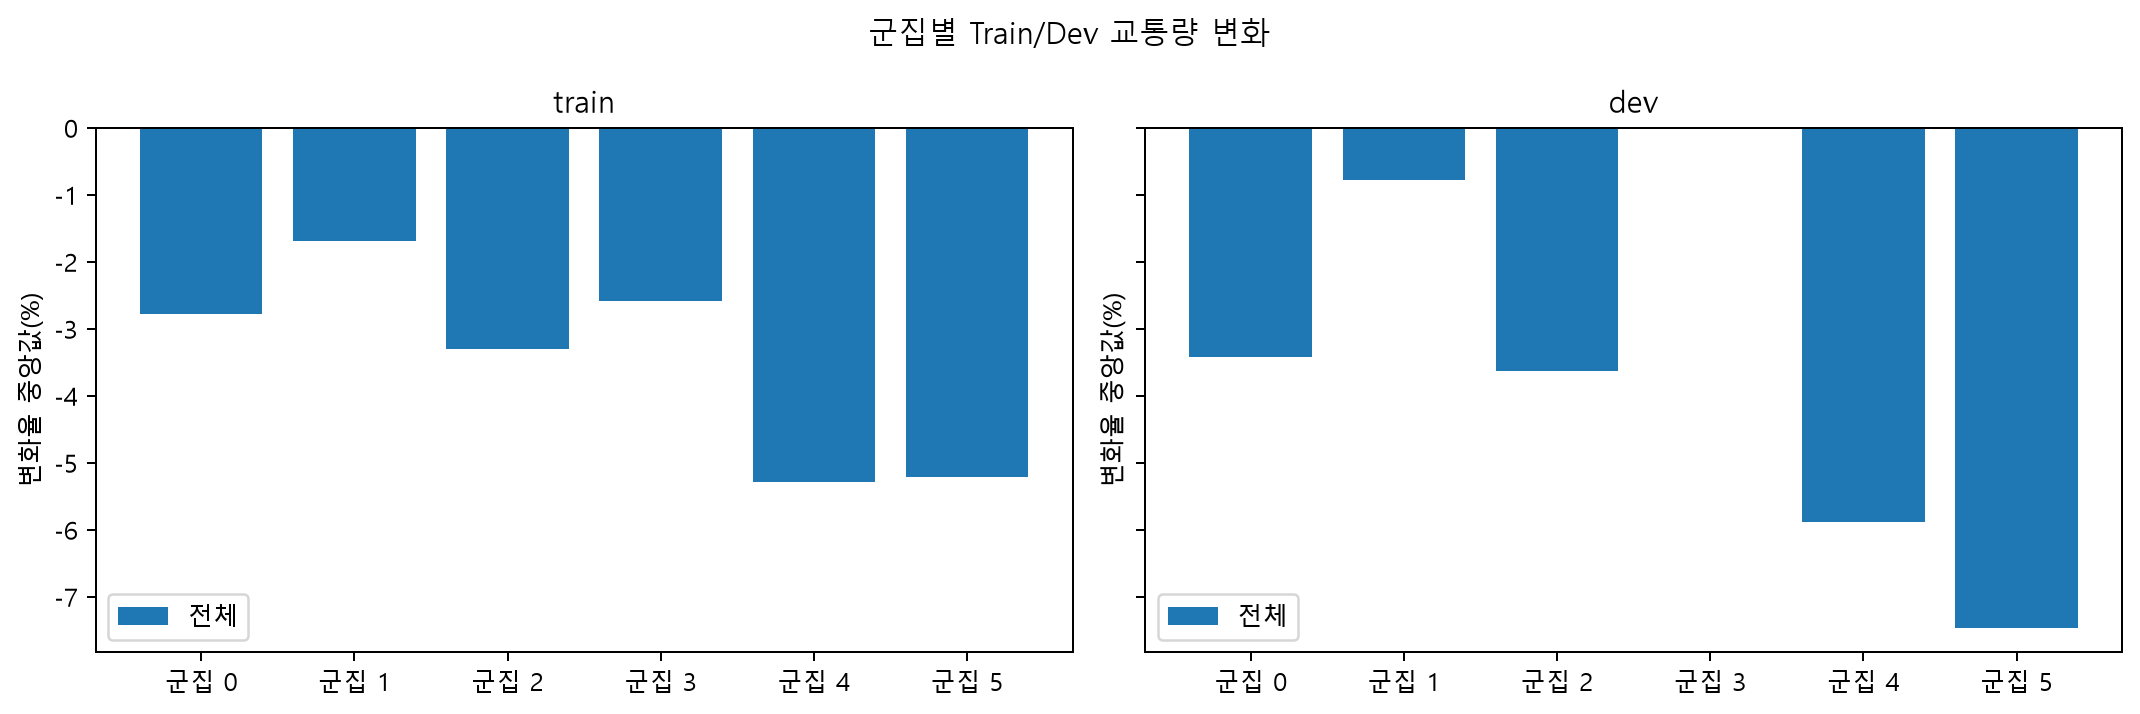

dtw_patterns_20261127T004149258567_(성공)_v01.png


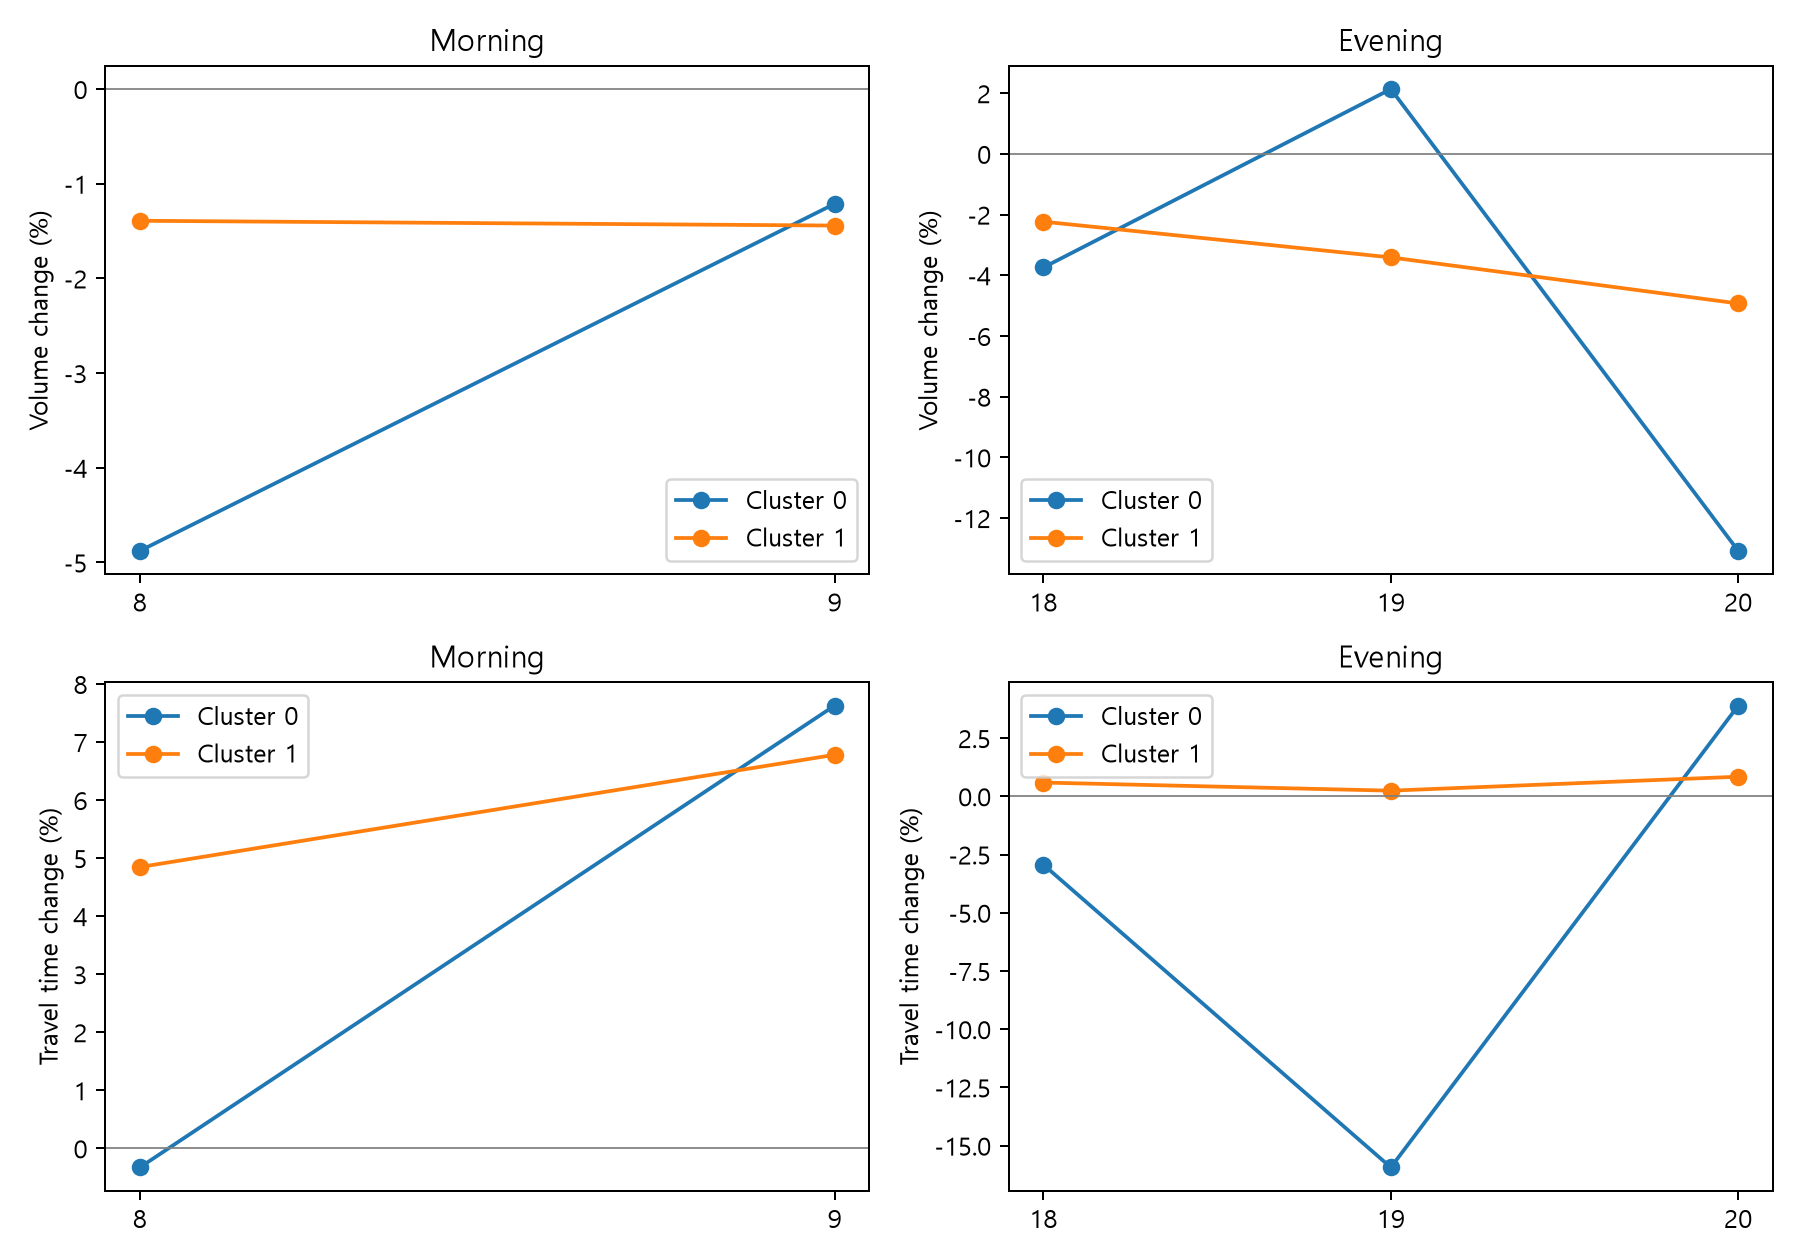

dtw_map_20261127T004206010068_(성공)_v01.png


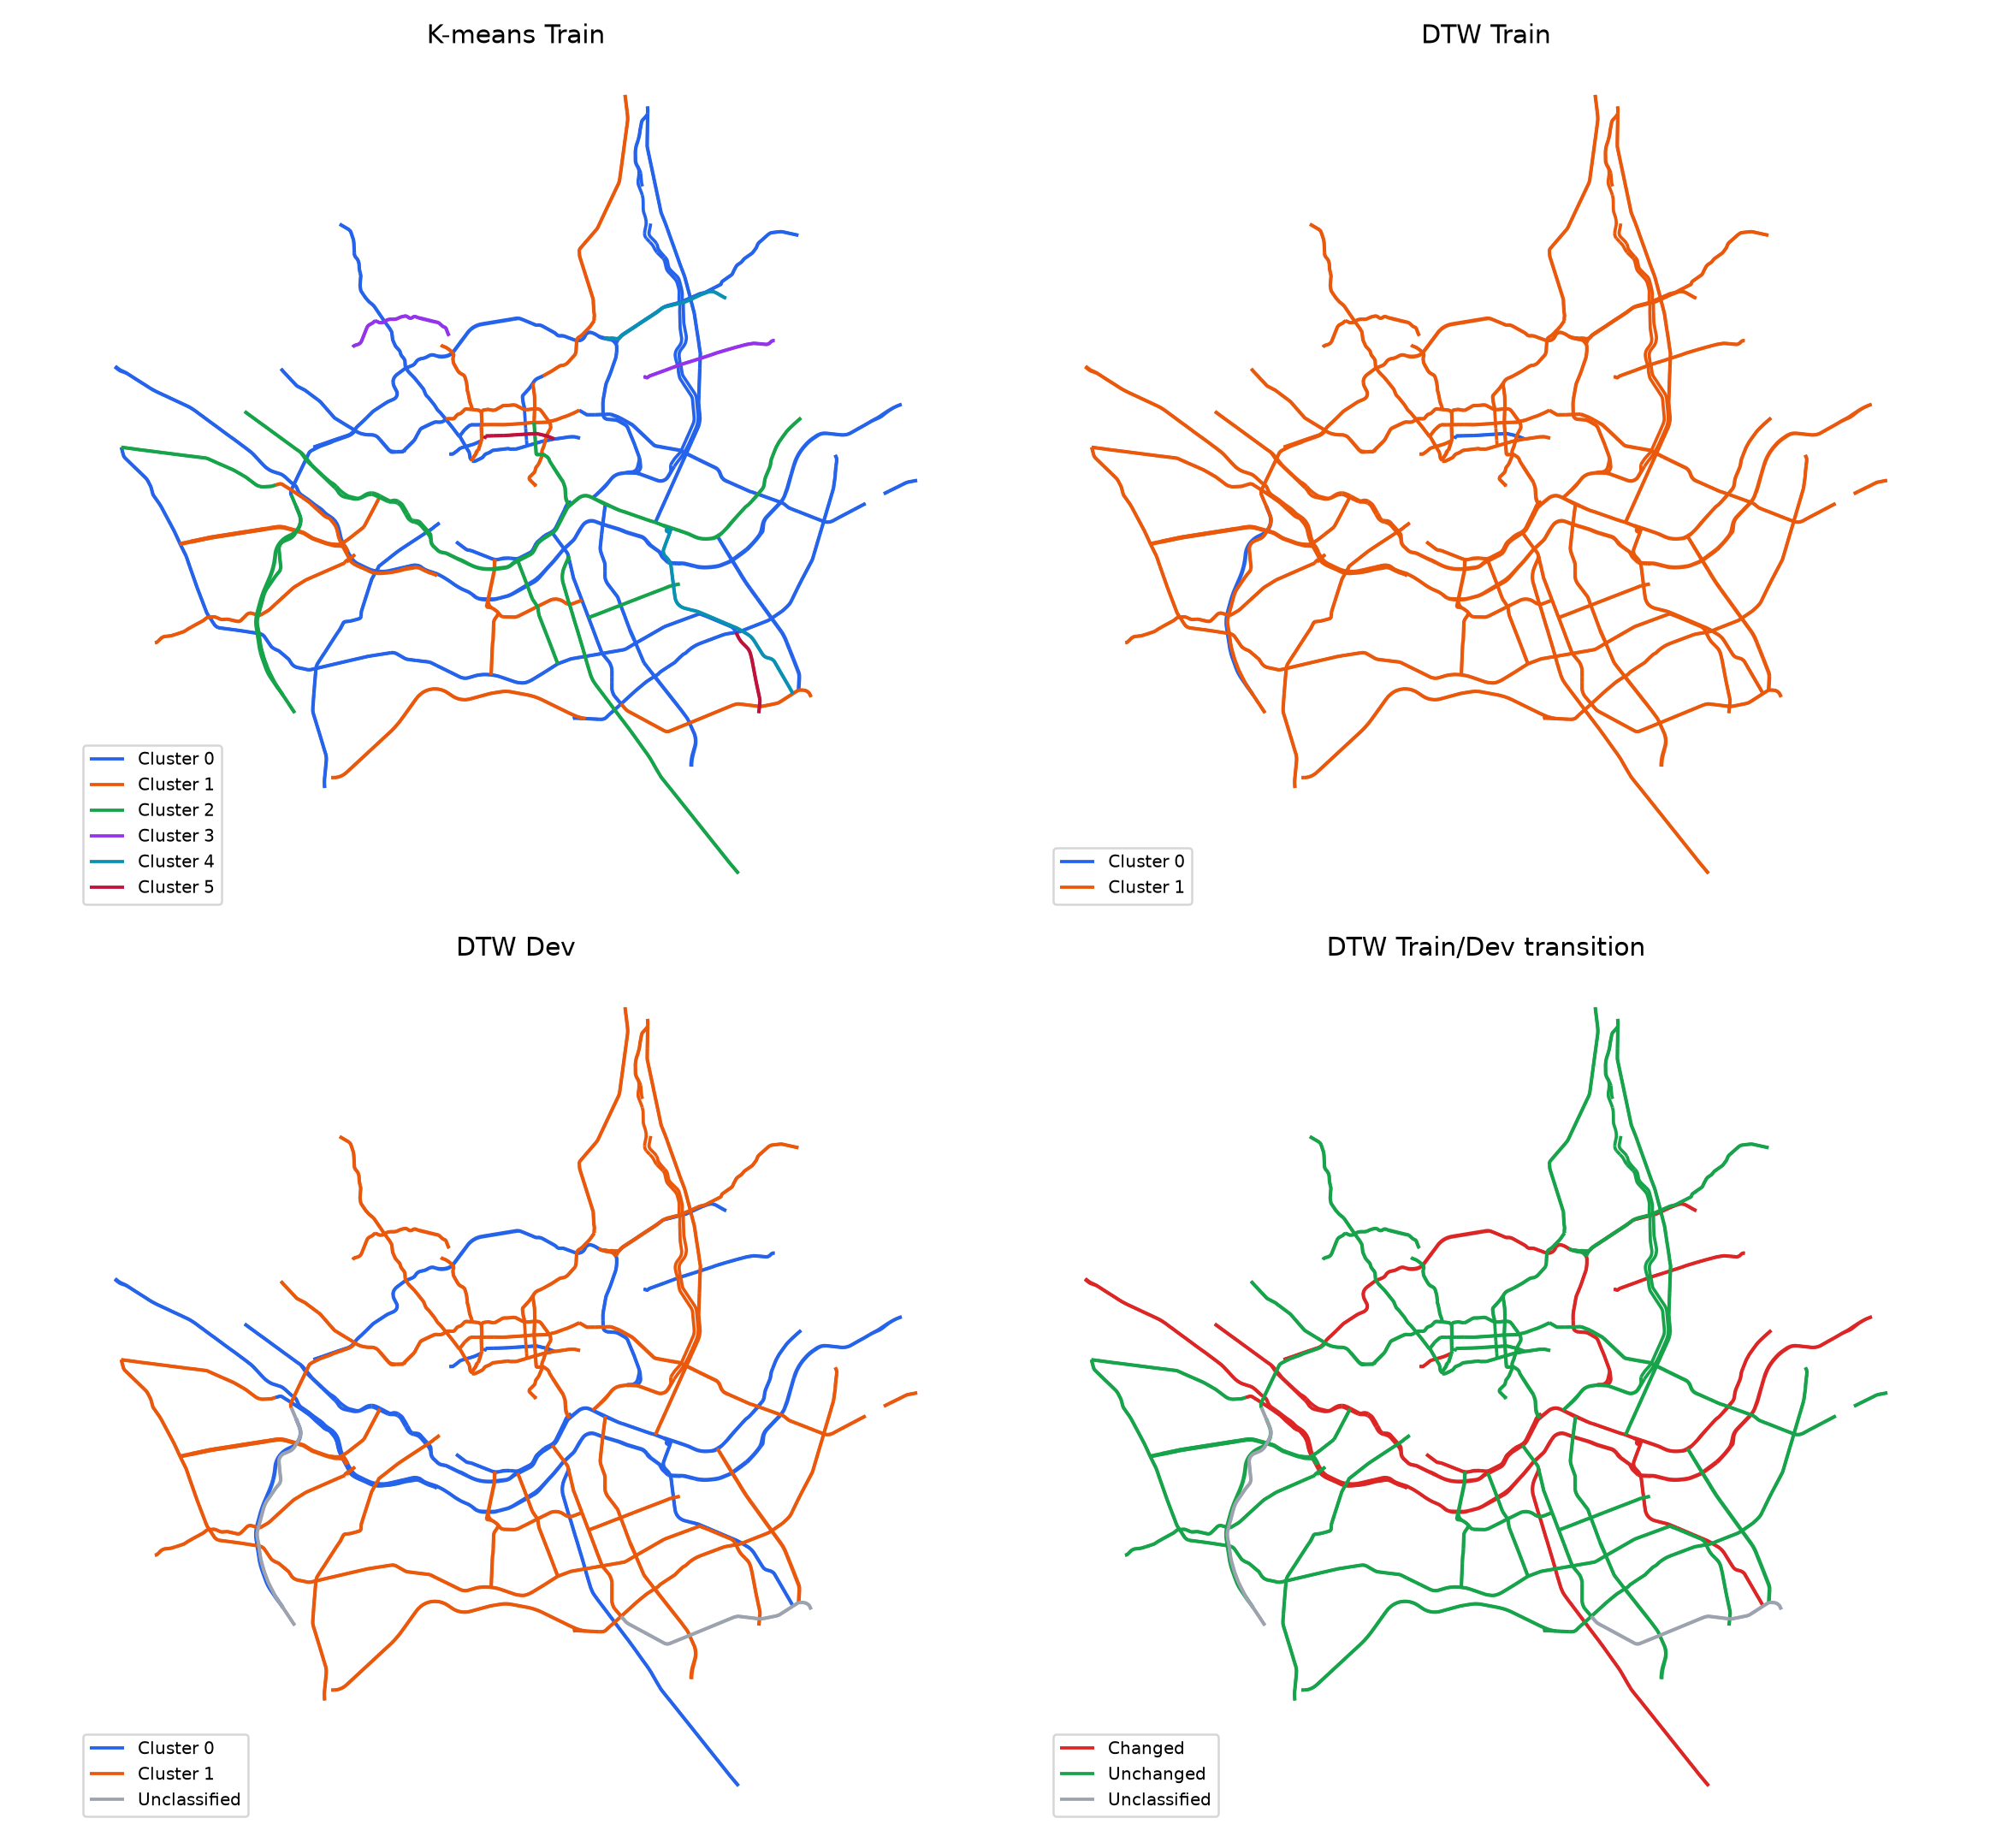

gi_hotspots_20261127T004236266537_(성공)_v01.png


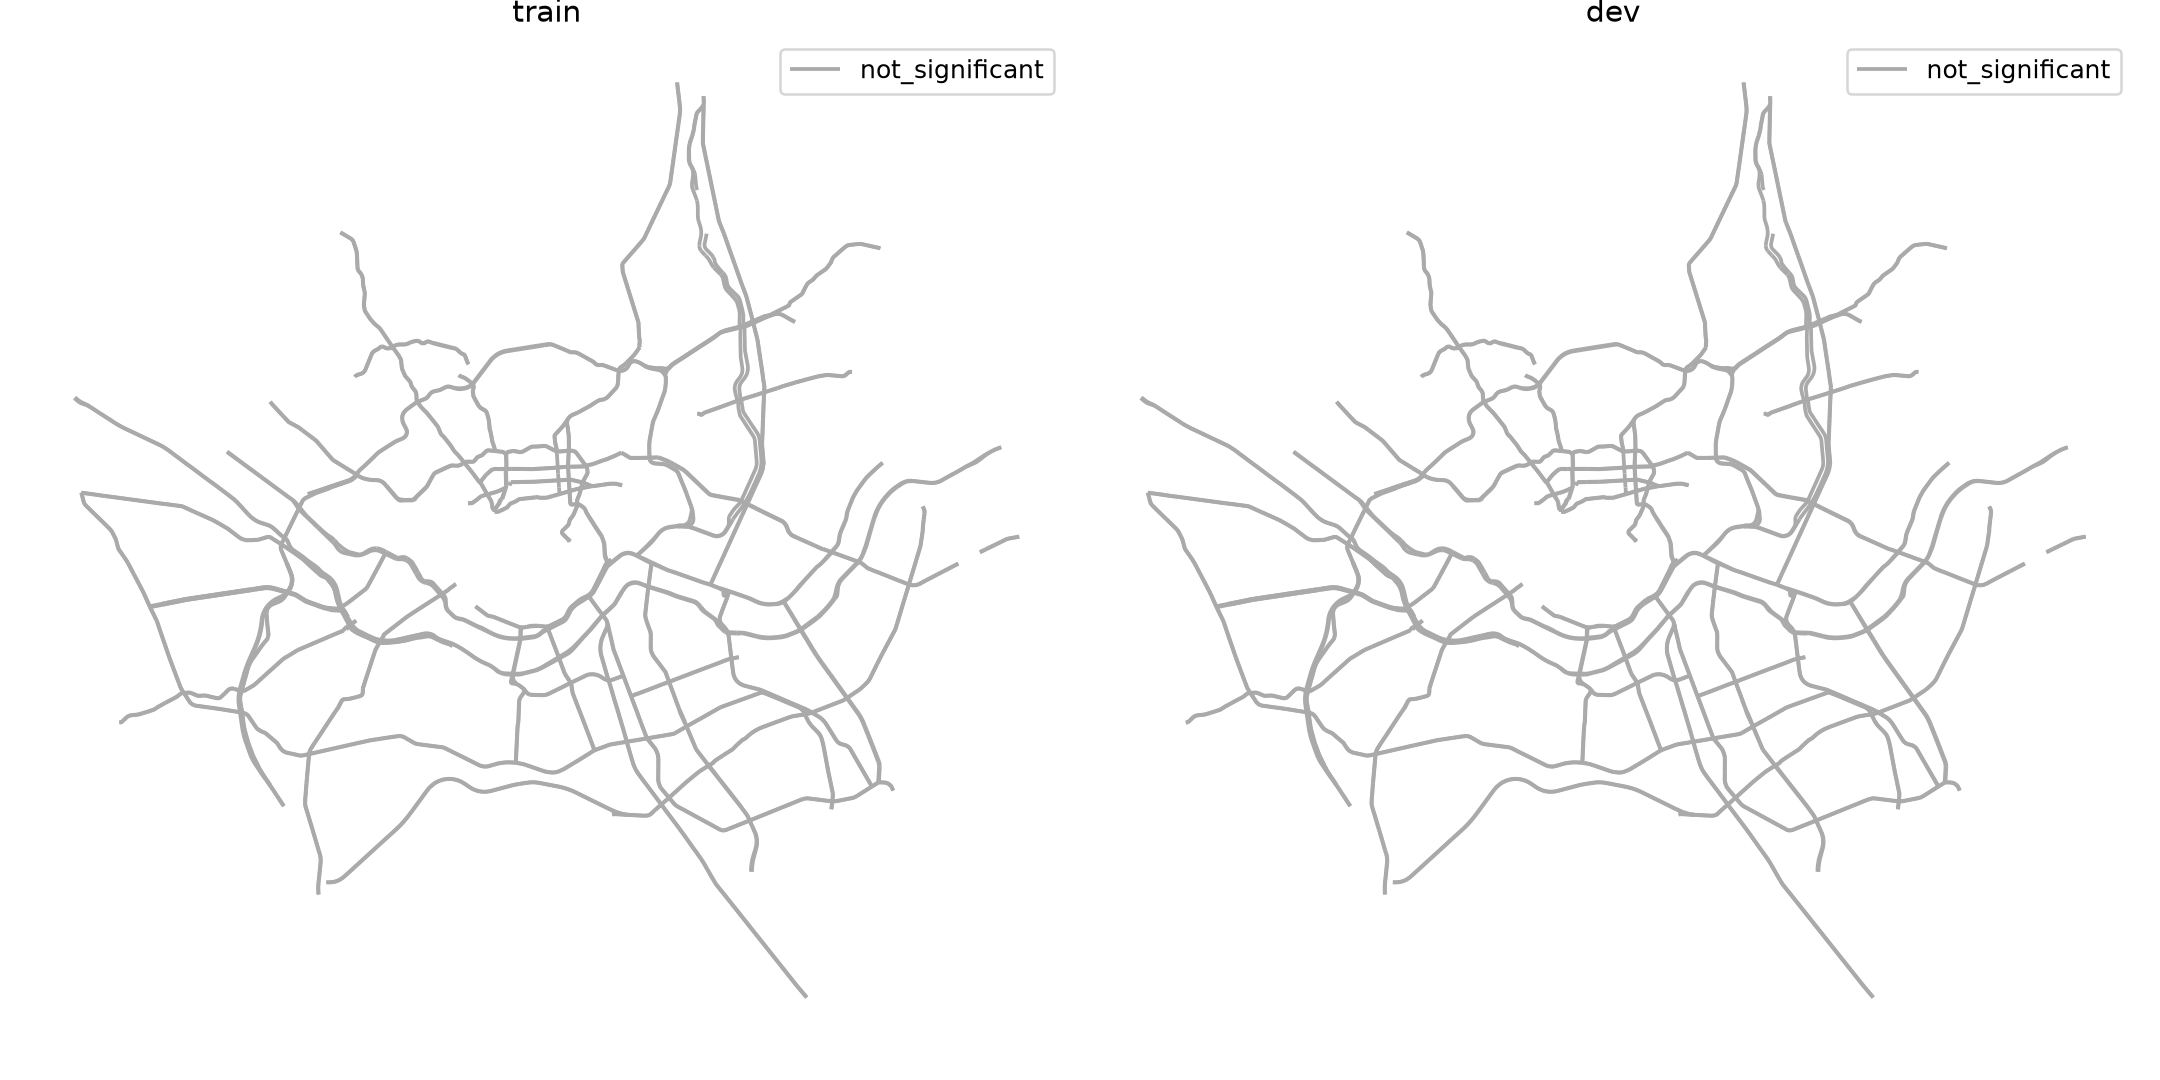

In [16]:
# [서연] 최신 핵심 그림
patterns = ['cluster_train_dev_*_(성공)_v*.png', 'dtw_patterns_*_(성공)_v*.png', 'dtw_map_*_(성공)_v*.png', 'gi_hotspots_*_(성공)_v*.png']
for pattern in patterns:
    path = sorted(FIGURES.glob(pattern))[-1]
    print(path.name)
    display(Image(filename=str(path), width=850))